# M2c: shared programs (top genes and GSEA)

Contract: `audit/contracts/M2c_programs.md` (decisions G1–G6). Python: `src/m2c_programs.py`; fgsea: `R/m2c_fgsea.R`
(tested in `tests/test_m2c.py`). This notebook reads their output files (written by `run_m2c(data, data/processed, seed=0)`) and shows them.

Two questions: (1) do cell types share their **strongest** genes? (2) do they run the same **programs** (Hallmark + KEGG gene sets)?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

pd.set_option("display.width", 160, "display.max_columns", 20, "display.max_colwidth", 60)
PROC = ROOT / "data/processed"
FILES = ["m2c_top_genes.csv", "m2c_top_sharing.csv", "m2c_jaccard.csv", "m2c_ranks.csv",
         "m2c_gene_set_coverage.csv", "m2c_gsea.csv", "m2c_programs.csv"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
LINKAGE = "average"  # decided (D2 row)

top = pd.read_csv(PROC / "m2c_top_genes.csv")
sharing = pd.read_csv(PROC / "m2c_top_sharing.csv")
jac = pd.read_csv(PROC / "m2c_jaccard.csv", index_col=[0, 1])
gsea = pd.read_csv(PROC / "m2c_gsea.csv")
programs = pd.read_csv(PROC / "m2c_programs.csv")
cov = pd.read_csv(PROC / "m2c_gene_set_coverage.csv")
CELL_TYPES = sorted(top["cell_type"].unique())

## 1. Every output file: shape, head and tail

In [2]:
for f in FILES:
    df = pd.read_csv(PROC / f)
    print(f"{f}: {df.shape}")
    display(df.head()); display(df.tail())

m2c_top_genes.csv: (294, 6)


,cell_type,direction,rank,gene,log2FC,qvalue
0,B cells,down,1,ID3,-1.104858,8.739390e-29
1,B cells,down,2,GSTP1,-1.299082,2.457874e-18
2,B cells,down,3,CD79B,-1.862004,9.165902e-17
3,B cells,down,4,LINC00926,-2.850318,1.401460e-13
4,B cells,down,5,HLA-DMA,-1.105340,2.531479e-12


,cell_type,direction,rank,gene,log2FC,qvalue
289,NK cells,up,16,IRF7,2.994474,9.847326e-35
290,NK cells,up,17,CD38,2.725716,1.794881e-34
291,NK cells,up,18,MT2A,3.738178,1.578589e-33
292,NK cells,up,19,OASL,2.091879,4.891345e-33
293,NK cells,up,20,RSAD2,5.601832,5.524998e-33


m2c_top_sharing.csv: (161, 11)


,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells,n_up,n_down
0,ISG20,↑,↑,↑,↑,↑,↑,↑,↑,8,0
1,IRF7,↑,↑,↑,–,↑,↑,–,↑,6,0
2,ISG15,↑,–,–,↑,↑,↑,↑,↑,6,0
3,PLSCR1,↑,↑,–,↑,↑,↑,–,↑,6,0
4,SAT1,↑,↑,↑,↑,–,–,↑,↑,6,0


...

,cell_type,collection,pathway,size,ES,NES,pval,padj,log2err,leadingEdge
0,B cells,hallmark,HALLMARK_ADIPOGENESIS,118,-0.318158,-1.286061,0.023788,0.151877,0.352488,UCP2;GPX4;ECH1;MGST3;ALDOA;CHCHD10;DHRS7;PIM3;PLIN2;TKT;...
1,B cells,hallmark,HALLMARK_ALLOGRAFT_REJECTION,123,0.529574,1.679363,0.001373,0.017533,0.455060,B2M;IRF7;HLA-E;SOCS1;TAP1;WARS;IRF8;HLA-A;STAT1;GBP2;SRG...
2,B cells,hallmark,HALLMARK_ANDROGEN_RESPONSE,51,0.613128,1.737676,0.003561,0.034773,0.431708,B2M;MYL12A;SAT1;TMEM50A;TNFAIP8;UBE2J1;ACSL3;FKBP5;SPCS3...
3,B cells,hallmark,HALLMARK_APICAL_JUNCTION,53,0.347222,0.991025,0.478375,0.799123,0.060248,NEXN;RAC2;EVL;JUP;AKT2;CD86;PTPRC;ICAM1;MDK;MYL12B;CD274...
4,B cells,hallmark,HALLMARK_APOPTOSIS,99,0.595922,1.849766,0.000083,0.001721,0.538434,ISG20;TNFSF10;SAT1;IFITM3;TAP1;DNAJA1;PMAIP1;IRF1;CD38;C...


,cell_type,collection,pathway,size,ES,NES,pval,padj,log2err,leadingEdge
1237,NK cells,kegg_legacy,KEGG_VASOPRESSIN_REGULATED_WATER_REABSORPTION,26,-0.277888,-0.856964,0.681818,0.987013,0.075118,ARHGDIB;VAMP2;DCTN1;DYNLL1;PRKACB;RAB11B
1238,NK cells,kegg_legacy,KEGG_VEGF_SIGNALING_PATHWAY,32,0.149111,0.410623,0.998420,1.000000,0.034865,SPHK1;PRKCB;PPP3R1;HSPB1;NFATC2
1239,NK cells,kegg_legacy,KEGG_VIBRIO_CHOLERAE_INFECTION,29,0.420732,1.131389,0.301613,0.654931,0.095288,KDELR2;SEC61B;ARF1;ATP6V1B2;SEC61G;PDIA4;SEC61A1;PRKCB;A...
1240,NK cells,kegg_legacy,KEGG_VIRAL_MYOCARDITIS,29,0.658554,1.770916,0.010505,0.059140,0.380730,PRF1;HLA-B;HLA-E;HLA-C;HLA-A;CASP3;CASP8;HLA-DRB1;HLA-DP...
1241,NK cells,kegg_legacy,KEGG_WNT_SIGNALING_PATHWAY,51,0.195158,0.581300,0.985185,1.000000,0.032433,PPP2R5C;CCND2;RBX1;CCND3;SKP1;MYC;PRKCB;JUN;PPP3R1


m2c_programs.csv: (58, 13)


,collection,pathway,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells,n_up,n_down,label
0,hallmark,HALLMARK_ADIPOGENESIS,–,↓,–,–,↓,↓,–,–,0,3,partial
1,hallmark,HALLMARK_ALLOGRAFT_REJECTION,↑,↑,↑,↑,↑,↑,–,↑,7,0,partial
2,hallmark,HALLMARK_ANDROGEN_RESPONSE,↑,–,–,↑,–,–,–,↑,3,0,partial
3,hallmark,HALLMARK_ANGIOGENESIS,n/t,↓,n/t,n/t,n/t,n/t,n/t,n/t,0,1,specific
4,hallmark,HALLMARK_APOPTOSIS,↑,↑,↑,↑,↑,↑,–,↑,7,0,partial


,collection,pathway,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells,n_up,n_down,label
53,kegg_legacy,KEGG_SYSTEMIC_LUPUS_ERYTHEMATOSUS,–,↑,–,–,–,↑,–,n/t,2,0,partial
54,kegg_legacy,KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY,–,↑,↑,–,↑,–,–,–,3,0,partial
55,kegg_legacy,KEGG_TRYPTOPHAN_METABOLISM,–,↑,–,n/t,–,–,n/t,n/t,1,0,specific
56,kegg_legacy,KEGG_TYPE_I_DIABETES_MELLITUS,–,↑,↑,↑,–,↑,–,↑,5,0,partial
57,kegg_legacy,KEGG_VIRAL_MYOCARDITIS,–,↑,–,–,–,–,–,–,1,0,specific


## 2. Gene sets: how many of their genes are in our data
Set genes are matched by exact symbol after the 6 B4 renames. Absent genes are listed, never fuzzily matched.
GSEA then only tests a set in a cell type if 15–500 of its genes are among that cell type's ranked (baseMean > 1) genes.

In [3]:
s = cov.groupby("collection").agg(sets=("pathway", "size"), genes=("n_genes", "sum"), found=("n_found", "sum"))
s["pct_found"] = (100 * s["found"] / s["genes"]).round(1)
display(s)
print("sets tested per cell type:"); display(gsea.groupby(["cell_type", "collection"]).size().unstack())

,sets,genes,found,pct_found
collection,,,,
hallmark,50,7322,6105,83.4
kegg_legacy,186,12801,9158,71.5


sets tested per cell type:


collection,hallmark,kegg_legacy
cell_type,,
B cells,45,121
CD14+ Monocytes,48,134
CD4 T cells,47,134
CD8 T cells,43,106
Dendritic cells,44,110
FCGR3A+ Monocytes,46,118
Megakaryocytes,41,53
NK cells,45,107


## 3. Top 20 up and top 20 down genes per cell type
Only DE genes (q < 0.05 and |log2FC| ≥ 1), ranked by q, then |log2FC|. Fewer than 20 where fewer are DE.

In [4]:
for d in ("up", "down"):
    t = top[top["direction"] == d]
    wide = t.assign(g=t["gene"] + " (" + t["log2FC"].round(1).astype(str) + ")").pivot(
        index="rank", columns="cell_type", values="g").reindex(columns=CELL_TYPES)
    print(f"Top 20 {d} (log2FC in brackets)"); display(wide.fillna(""))

Top 20 up (log2FC in brackets)


cell_type,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells
rank,,,,,,,,
1,ISG20 (3.4),ISG20 (5.8),ISG20 (3.0),ISG20 (3.4),ISG15 (6.2),APOBEC3A (4.4),ISG15 (5.6),ISG15 (4.7)
2,ISG15 (5.6),IL1RN (6.7),TNFSF10 (4.5),ISG15 (4.8),ISG20 (3.8),ISG20 (4.5),ISG20 (3.4),ISG20 (3.7)
3,LY6E (4.2),DYNLT1 (2.8),PSMB9 (1.7),IFI6 (5.3),IFI6 (5.6),TNFSF10 (4.1),IFI6 (4.7),IFIT1 (6.2)
4,IRF7 (3.8),SSB (3.4),BST2 (2.5),IFIT1 (5.8),IFITM3 (5.9),IFIT3 (5.2),IFIT1 (7.9),TNFSF10 (3.3)
5,UBE2L6 (2.8),IFITM2 (4.9),IRF7 (3.5),LY6E (3.5),LY6E (5.0),IFIT2 (5.5),IFIT2 (7.8),PRF1 (2.2)
6,MYL12A (1.5),TMSB10 (2.2),DRAP1 (2.0),IFIT3 (6.4),IRF7 (3.7),OAS1 (2.7),IFIT3 (7.3),PLSCR1 (4.1)
7,PSMB9 (2.0),NT5C3A (5.9),MT2A (4.2),MT2A (4.6),MX1 (5.8),MYL12A (1.5),RSAD2 (7.1),MX1 (4.4)
8,TNFSF10 (6.5),IRF7 (3.5),SAT1 (2.7),MX1 (5.3),OAS1 (5.6),SSB (2.6),LY6E (4.3),ANXA1 (1.5)
9,IFITM2 (2.9),MYL12A (2.0),GBP1 (3.8),SAMD9 (2.8),CXCL11 (8.3),TMSB10 (1.7),TNFSF10 (6.1),UBE2L6 (2.0)


Top 20 down (log2FC in brackets)


cell_type,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells
rank,,,,,,,,
1,ID3 (-1.1),RPL6 (-1.7),RGCC (-1.1),AMICA1 (-1.7),INSIG1 (-2.7),ARHGDIB (-1.8),FTL (-1.7),FGFBP2 (-1.3)
2,GSTP1 (-1.3),RPL7 (-1.3),AMICA1 (-1.7),TUBA4A (-1.3),VMO1 (-3.8),RPL6 (-1.1),FTH1 (-1.6),PRDX5 (-1.0)
3,CD79B (-1.9),CLEC5A (-4.7),NELL2 (-1.6),FGFBP2 (-1.2),CD9 (-3.1),ENO1 (-1.4),IL8 (-4.8),RAMP1 (-2.2)
4,LINC00926 (-2.9),VCAN (-4.4),NSMCE1 (-1.1),ANP32A (-1.1),CXCL16 (-2.5),GPX1 (-1.3),S100A8 (-4.1),HOPX (-1.0)
5,HLA-DMA (-1.1),RGCC (-2.6),CD27 (-1.2),GCHFR (-1.0),IL1R2 (-4.5),CD14 (-2.9),,TAGLN2 (-1.1)
6,CTSH (-1.3),GLIPR1 (-2.3),TUBA4A (-1.2),FAM102A (-1.7),GLIPR1 (-2.8),LTA4H (-3.2),,ITM2A (-1.3)
7,LSP1 (-1.4),MARCKSL1 (-1.6),ARRDC2 (-1.2),GZMM (-1.1),AMICA1 (-4.1),S100A8 (-2.7),,EIF3L (-1.3)
8,ZFP36L2 (-1.0),RPL10A (-1.4),SIT1 (-1.6),GTF3C1 (-1.5),GPX1 (-1.3),RGCC (-2.6),,GPX1 (-1.6)
9,PRDX5 (-1.1),S100A8 (-1.9),IL8 (-2.2),TYROBP (-1.2),CD36 (-2.8),CD44 (-1.2),,S100A4 (-1.3)


## 4. Which genes are in the top 20 of several cell types?
One row per gene in any top list; ↑ / ↓ = in that cell type's top 20 up / down; – = not in its top 20 (it may still be DE).

In [5]:
for d, col in (("up", "n_up"), ("down", "n_down")):
    print(f"\nTop-20 {d}, by number of cell types:")
    for k, g in sharing[sharing[col] > 0].groupby(col, sort=False)["gene"]:
        print(f"  in {k} cell types ({len(g)}): {', '.join(sorted(g))}")
display(sharing[(sharing["n_up"] + sharing["n_down"]) >= 3])


Top-20 up, by number of cell types:
  in 8 cell types (1): ISG20
  in 6 cell types (5): IRF7, ISG15, PLSCR1, SAT1, TNFSF10
  in 5 cell types (7): IFI6, IFIT3, LY6E, MX1, OASL, TMSB10, UBE2L6
  in 4 cell types (6): BST2, IFIT1, MT2A, MYL12A, OAS1, RSAD2
  in 3 cell types (6): DYNLT1, HERC5, IFIT2, IFITM3, PSMB9, PSME2
  in 2 cell types (10): DRAP1, EPSTI1, GBP1, IFI35, IFI44L, IFITM2, NT5C3A, SAMD9, SAMD9L, SSB
  in 1 cell types (25): ANXA1, APOBEC3A, CCL8, CD38, CMPK2, CXCL10, CXCL11, DDX58, HLA-E, HSPA1A, HSPB1, IDO1, IFI16, IL1RN, IL4I1, MS4A6A, MX2, NAGK, NMI, PRF1, PSMA2.1, PSMB8, RTCB, TMEM50A, TRIM22

Top-20 down, by number of cell types:
  in 5 cell types (1): IL8
  in 4 cell types (1): GLIPR1
  in 3 cell types (5): AMICA1, GPX1, PRDX5, RGCC, S100A8
  in 2 cell types (16): ARHGDIB, CD14, CD9, EIF3L, ENO1, FGFBP2, GSTP1, GTF3C1, ID3, IL1B, INSIG1, RPL23, RPL5, RPL6, TUBA4A, VCAN
  in 1 cell types (78): ALOX5AP, ANP32A, AOAH, AQP3, ARRDC2, C10orf54, C16orf74, C19orf59, CCL22, CD2

,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells,n_up,n_down
0,ISG20,↑,↑,↑,↑,↑,↑,↑,↑,8,0
1,IRF7,↑,↑,↑,–,↑,↑,–,↑,6,0
2,ISG15,↑,–,–,↑,↑,↑,↑,↑,6,0
3,PLSCR1,↑,↑,–,↑,↑,↑,–,↑,6,0
4,SAT1,↑,↑,↑,↑,–,–,↑,↑,6,0
5,TNFSF10,↑,–,↑,↑,–,↑,↑,↑,6,0
6,IFI6,–,–,↑,↑,↑,–,↑,↑,5,0
7,IFIT3,–,–,–,↑,↑,↑,↑,↑,5,0
8,LY6E,↑,–,–,↑,↑,↑,↑,–,5,0
9,MX1,–,–,–,↑,↑,↑,↑,↑,5,0


## 5. Which cell types share their full DE lists? (Jaccard)
Jaccard = shared DE genes / DE genes in either cell type, up and down separately (1 = identical lists, 0 = no overlap).
Cell types are clustered on 1 − Jaccard; the dendrogram shows which cell types group together.

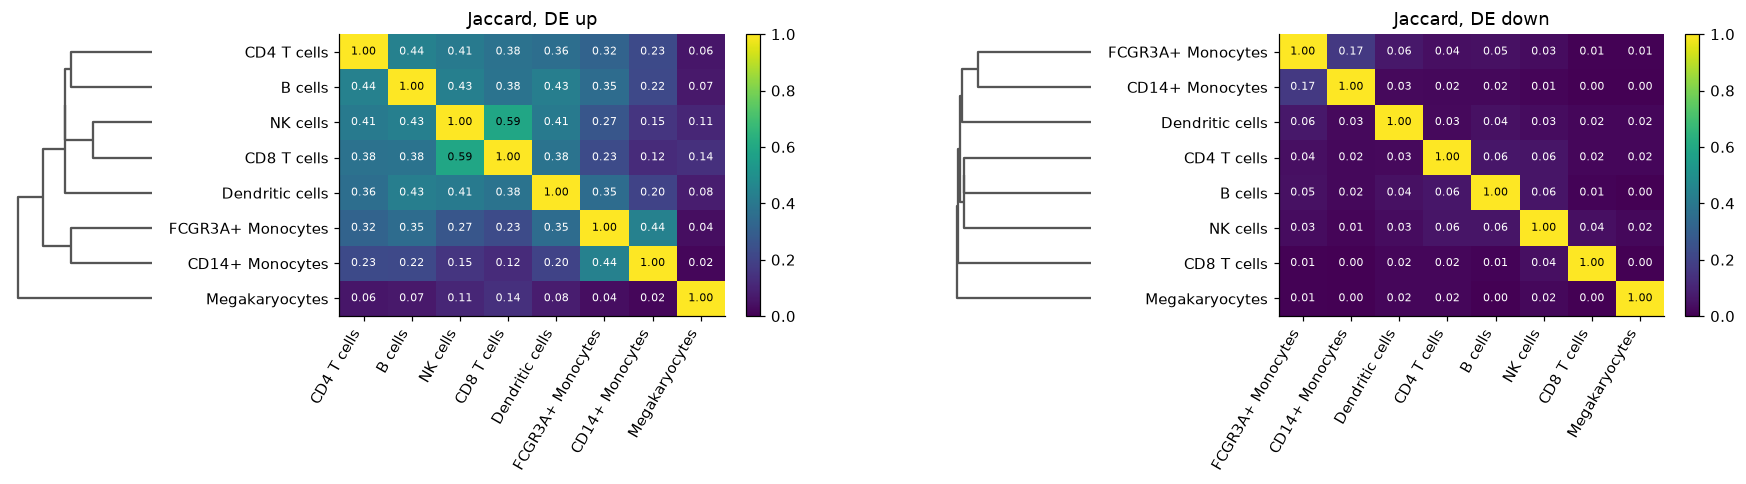


DE up: groups when the tree is cut into 2, 3, 4 clusters
  k=2: B cells, CD14+ Monocytes, CD4 T cells, CD8 T cells, Dendritic cells, FCGR3A+ Monocytes, NK cells | Megakaryocytes
  k=3: CD14+ Monocytes, FCGR3A+ Monocytes | B cells, CD4 T cells, CD8 T cells, Dendritic cells, NK cells | Megakaryocytes
  k=4: CD14+ Monocytes, FCGR3A+ Monocytes | B cells, CD4 T cells, CD8 T cells, NK cells | Dendritic cells | Megakaryocytes

DE down: groups when the tree is cut into 2, 3, 4 clusters
  k=2: B cells, CD14+ Monocytes, CD4 T cells, CD8 T cells, Dendritic cells, FCGR3A+ Monocytes, NK cells | Megakaryocytes
  k=3: B cells, CD14+ Monocytes, CD4 T cells, Dendritic cells, FCGR3A+ Monocytes, NK cells | CD8 T cells | Megakaryocytes
  k=4: B cells, CD4 T cells, NK cells | CD14+ Monocytes, Dendritic cells, FCGR3A+ Monocytes | CD8 T cells | Megakaryocytes


In [6]:
def heatmap_with_tree(mat, dist, title, ax_tree, ax_map, fmt="{:.2f}", cmap="viridis", vmin=0, vmax=1, marks=None):
    """Heatmap with rows/columns ordered by a dendrogram of `dist` (condensed); returns the linkage."""
    Z = linkage(dist, method=LINKAGE)
    order = dendrogram(Z, labels=list(mat.index), ax=ax_tree, orientation="left", color_threshold=0,
                       above_threshold_color="#555")["ivl"][::-1]
    ax_tree.set_axis_off()
    m = mat.loc[order]
    if m.shape[0] == m.shape[1]:
        m = m[order]
    im = ax_map.imshow(m.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax_map.set_xticks(range(m.shape[1]), m.columns, rotation=60, ha="right"); ax_map.set_yticks(range(m.shape[0]), m.index)
    if fmt:
        for i in range(m.shape[0]):
            for j in range(m.shape[1]):
                ax_map.text(j, i, fmt.format(m.iat[i, j]), ha="center", va="center", fontsize=7,
                            color="white" if m.iat[i, j] < (vmin + vmax) / 2 else "black")
    if marks is not None:
        mk = marks.loc[m.index, m.columns]
        ys, xs = np.nonzero(mk.to_numpy())
        ax_map.scatter(xs, ys, s=6, c="black", marker="o")
    ax_map.set_title(title)
    plt.colorbar(im, ax=ax_map, fraction=0.04)
    return Z


fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 3, 1, 3]})
jac_groups = {}
for k, d in enumerate(("up", "down")):
    m = jac.loc[d][CELL_TYPES]
    assert not m.isna().any().any(), "Jaccard undefined (two empty DE sets)"
    Z = heatmap_with_tree(m, squareform(1 - m.to_numpy(), checks=False), f"Jaccard, DE {d}", axes[2 * k], axes[2 * k + 1])
    jac_groups[d] = Z
plt.tight_layout(); plt.show()

for d, Z in jac_groups.items():
    print(f"\nDE {d}: groups when the tree is cut into 2, 3, 4 clusters")
    for k in (2, 3, 4):
        lab = fcluster(Z, k, criterion="maxclust")
        print(f"  k={k}:", " | ".join(", ".join(c for c, l in zip(CELL_TYPES, lab) if l == g) for g in sorted(set(lab))))

## 6. Programs: NES heatmap
NES > 0: the gene set sits towards the up-regulated end of the cell type's ranking (Wald statistic); NES < 0: towards the down end.
Rows = every program affected (BH-adjusted p < 0.05) in at least one cell type; dots = affected in that cell type.
Rows and columns are clustered on correlation distance (1 − Pearson r) of NES. Grey hatched **n/t** = set not tested there (fewer than 15 or more than 500 of its genes ranked).

programs affected anywhere: 58; NES missing (set untested) in 30 cells
programs with NES in all 8 cell types (used for clustering): 46


/var/folders/yg/c2qs60xj6k781zdj1nl219zr0000gn/T/ipykernel_76393/1042672286.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  nes_aff, sig_aff = nes.loc[rows], sig.loc[rows].fillna(False).astype(bool)


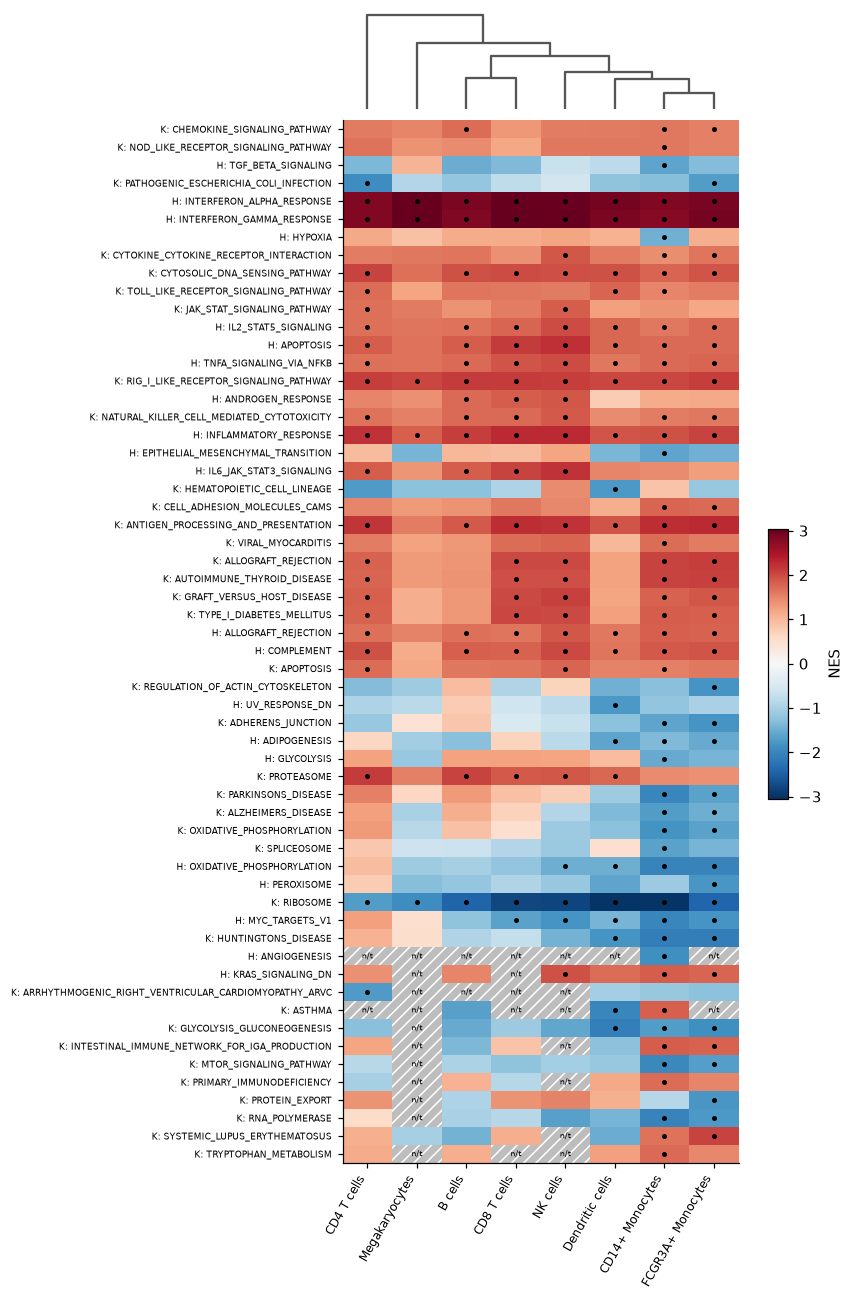

Cell-type groups from NES (correlation distance):
  k=2: B cells, CD14+ Monocytes, CD8 T cells, Dendritic cells, FCGR3A+ Monocytes, Megakaryocytes, NK cells | CD4 T cells
  k=3: B cells, CD14+ Monocytes, CD8 T cells, Dendritic cells, FCGR3A+ Monocytes, NK cells | Megakaryocytes | CD4 T cells
  k=4: B cells, CD8 T cells | CD14+ Monocytes, Dendritic cells, FCGR3A+ Monocytes, NK cells | Megakaryocytes | CD4 T cells

NES correlation between cell types (affected programs with complete NES):


cell_type,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells
cell_type,,,,,,,,
B cells,1.00,0.75,0.74,0.91,0.83,0.81,0.74,0.86
CD14+ Monocytes,0.75,1.00,0.65,0.84,0.88,0.95,0.82,0.90
CD4 T cells,0.74,0.65,1.00,0.83,0.78,0.73,0.70,0.65
CD8 T cells,0.91,0.84,0.83,1.00,0.88,0.89,0.77,0.90
Dendritic cells,0.83,0.88,0.78,0.88,1.00,0.94,0.87,0.88
FCGR3A+ Monocytes,0.81,0.95,0.73,0.89,0.94,1.00,0.88,0.89
Megakaryocytes,0.74,0.82,0.70,0.77,0.87,0.88,1.00,0.76
NK cells,0.86,0.90,0.65,0.90,0.88,0.89,0.76,1.00


In [7]:
nes = gsea.pivot(index="pathway", columns="cell_type", values="NES").reindex(columns=CELL_TYPES)
sig = gsea.assign(s=gsea["padj"] < 0.05).pivot(index="pathway", columns="cell_type", values="s").reindex(columns=CELL_TYPES)
rows = programs["pathway"]
nes_aff, sig_aff = nes.loc[rows], sig.loc[rows].fillna(False).astype(bool)
print(f"programs affected anywhere: {len(rows)}; NES missing (set untested) in {int(nes_aff.isna().sum().sum())} cells")
complete = nes_aff.dropna()  # display only: correlation needs complete rows; counts reported above
print(f"programs with NES in all 8 cell types (used for clustering): {len(complete)}")

Zc = linkage(complete.T.to_numpy(), method=LINKAGE, metric="correlation")
Zr = linkage(complete.to_numpy(), method=LINKAGE, metric="correlation")
col_order = [CELL_TYPES[i] for i in dendrogram(Zc, no_plot=True)["leaves"]]
row_order = [complete.index[i] for i in dendrogram(Zr, no_plot=True)["leaves"]]
row_order += [p for p in nes_aff.index if p not in row_order]  # untested-somewhere programs at the bottom
lim = np.nanmax(np.abs(nes_aff.to_numpy()))

H = 0.16 * len(row_order) + 3
fig = plt.figure(figsize=(9, H))
ax_top = fig.add_axes([0.45, 1 - 1.1 / H, 0.4, 0.9 / H])
dendrogram(Zc, ax=ax_top, color_threshold=0, above_threshold_color="#555", no_labels=True)
ax_top.set_xlim(0, 10 * len(col_order)); ax_top.set_axis_off()  # leaves sit at 5, 15, ... = column centres
ax = fig.add_axes([0.45, 1.6 / H, 0.4, 1 - 2.8 / H])
cax = fig.add_axes([0.88, 0.4, 0.02, 0.2])
m = nes_aff.loc[row_order, col_order]
ax.set_facecolor("#bdbdbd")  # n/t (not tested: set size outside 15-500) = grey cells, hatched
im = ax.imshow(m.to_numpy(dtype=float), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for y, x in zip(*np.nonzero(m.isna().to_numpy())):
    ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor="#bdbdbd", hatch="///", edgecolor="white", lw=0))
    ax.text(x, y, "n/t", ha="center", va="center", fontsize=5)
ys, xs = np.nonzero(sig_aff.loc[row_order, col_order].to_numpy())
ax.scatter(xs, ys, s=5, c="black")
ax.set_xticks(range(len(col_order)), col_order, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(row_order)), [p.replace("HALLMARK_", "H: ").replace("KEGG_", "K: ") for p in row_order], fontsize=6)
fig.colorbar(im, cax=cax, label="NES")
plt.show()

print("Cell-type groups from NES (correlation distance):")
for k in (2, 3, 4):
    lab = fcluster(Zc, k, criterion="maxclust")
    print(f"  k={k}:", " | ".join(", ".join(c for c, l in zip(CELL_TYPES, lab) if l == g) for g in sorted(set(lab))))
print("\nNES correlation between cell types (affected programs with complete NES):")
display(complete.corr().round(2))

## 7. Program labels across the 8 cell types
**shared** = affected in all 8, same direction; **partial** = 2–7, same direction; **specific** = 1;
**mixed** = affected up in some cell types and down in others. Not affected anywhere → not listed.
In `m2c_programs.csv`: ↑ / ↓ affected; – tested, not affected; **n/t** not tested (counts as not affected).

In [8]:
programs["direction"] = np.where(programs["label"] == "mixed", "mixed",
                                 np.where(programs["n_up"] > 0, "up", "down"))
display(pd.crosstab([programs["collection"]], [programs["label"], programs["direction"]], margins=True))
nt = (programs[CELL_TYPES] == "n/t")
print(f"n/t cells: {int(nt.sum().sum())} in {int(nt.any(axis=1).sum())} programs; per cell type:", nt.sum().to_dict())
for (lab, d), g in programs.groupby(["label", "direction"]):
    if lab == "mixed":
        items = [f"{p} (↑{u}/↓{n})" for p, u, n in zip(g["pathway"], g["n_up"], g["n_down"])]
    elif lab == "specific":
        items = [f"{p} [{next(c for c in CELL_TYPES if r[c] in ('↑', '↓'))}]" for p, (_, r) in zip(g["pathway"], g.iterrows())]
    else:
        items = [f"{p} ({u + n})" for p, u, n in zip(g["pathway"], g["n_up"], g["n_down"])]
    print(f"\n{lab} / {d} ({len(g)}): " + "; ".join(sorted(items)))

label       mixed partial     shared    specific    All
direction   mixed    down  up   down up     down up    
collection                                             
hallmark        0       3   8      0  3        7  0  21
kegg_legacy     1       9  16      1  1        5  4  37
All             1      12  24      1  4       12  4  58

n/t cells: 30 in 12 programs; per cell type: {'B cells': 2, 'CD14+ Monocytes': 0, 'CD4 T cells': 2, 'CD8 T cells': 5, 'Dendritic cells': 1, 'FCGR3A+ Monocytes': 2, 'Megakaryocytes': 11, 'NK cells': 7}

mixed / mixed (1): KEGG_ASTHMA (↑1/↓1)

partial / down (12): HALLMARK_ADIPOGENESIS (3); HALLMARK_MYC_TARGETS_V1 (5); HALLMARK_OXIDATIVE_PHOSPHORYLATION (4); KEGG_ADHERENS_JUNCTION (2); KEGG_ALZHEIMERS_DISEASE (2); KEGG_GLYCOLYSIS_GLUCONEOGENESIS (3); KEGG_HUNTINGTONS_DISEASE (3); KEGG_MTOR_SIGNALING_PATHWAY (2); KEGG_OXIDATIVE_PHOSPHORYLATION (2); KEGG_PARKINSONS_DISEASE (2); KEGG_PATHOGENIC_ESCHERICHIA_COLI_INFECTION (2); KEGG_RNA_POLYMERASE (2)

partial / up (24): HALLMARK_ALLOGRAFT_REJECTION (7); HALLMARK_ANDROGEN_RESPONSE (3); HALLMARK_APOPTOSIS (7); HALLMARK_COMPLEMENT (7); HALLMARK_IL2_STAT5_SIGNALING (7); HALLMARK_IL6_JAK_STAT3_SIGNALING (4); HALLMARK_KRAS_SIGNALING_DN (3); HALLMARK_TNFA_SIGNALING_VIA_NFKB (7); KEGG_ALLOGRAFT_REJECTION (5); KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION

## 8. Sanity check: IFN programs
Hallmark IFN-α and IFN-γ response should be up in every cell type (M3 scores are up in all 8).

In [9]:
display(gsea[gsea["pathway"].str.contains("INTERFERON")].pivot(
    index="cell_type", columns="pathway", values=["NES", "padj"]).round(4))

NES                                                                  padj                                   
pathway           HALLMARK_INTERFERON_ALPHA_RESPONSE HALLMARK_INTERFERON_GAMMA_RESPONSE HALLMARK_INTERFERON_ALPHA_RESPONSE HALLMARK_INTERFERON_GAMMA_RESPONSE
cell_type                                                                                                                                                    
B cells                                       2.8748                             2.8349                                0.0                                0.0
CD14+ Monocytes                               2.8283                             2.7715                                0.0                                0.0
CD4 T cells                                   2.8141                             2.8142                                0.0                                0.0
CD8 T cells                                   3.0495                             3.0312                                0.0                                0.0
Dendritic cells                               2.9172                             2.8758                                0.0                                0.0
FCGR3A+ Monocytes                             2.9011                             2.9286                                0.0                                0.0
Megakaryocytes                                3.0438                             3.0404                                0.0                                0.0
NK cells                                      3.0250                             3.0447                                0.0                                0.0